# Parameter estimation for a coffee berry borer infestation model using field data

## Import necessary libraries

In [1]:
import sys  
sys.path.insert(0, '../pyscripts/')
from pathlib import Path
import matplotlib.pyplot as plt
%matplotlib inline
from models_cls import initiate
from calibration_cls import estimation

## Model parameters
Read the values of the model parameters held fixed during the fitting process.

In [2]:
switch = False # use reproduction rate constant (False) or variable (True)
phi = 0 # coffee harvest percentage
b0 = 0 # initial amount of borers, one of the parameters to vary 
mu = None
if switch:
    params_file = Path('..') / 'data' / 'params_varrepro_fixed.csv'
else:
    params_file = Path('..') / 'data' / 'params_constrepro_fixed.csv'
initiate_simulations = initiate(switch, phi, b0, mu, params_file)
parameters = initiate_simulations.parameter_values()
df_params = initiate_simulations.df # dataframe of the parameter values

## Solve the least-squares problem
Print tables: model parameters, data, model outcomes, and optimum.
Plot: fitting.

Model parameters:


,Value,Description
Parameter,,
coffee_total,1000.0,total number of coffee berries in the season (berry/tree)
kappa_b_berry,20.0,CBB carrying capacity per berry (CBB/berry)
rho_b,0.0345,CBB reproduction rate (1/day) at 24 C Jaramillo et al 2009
epsbe2rhob,0.75,"ratio of exiting to reproduction rate (0, 1)"
del_b,0.001,free-borer death rate (1/day) Romero and Cortina 2007
cu0,1.0,value to scale the total number of coffee berries
t0,0.0,season starting time (day)
th,184.0,harvesting time (day)
tf,364.0,season ending time (day)


 
Field dataset of coffee infestation (%):


,June,September,October,November
Year,,,,
2010,1.67,5.62,7.34,12.41
2011,15.98,46.43,51.37,58.37
2015,5.58,6.21,9.16,11.02
2018,21.22,25.35,32.31,44.05


 
Model-predicted values of coffee infestation (%):


,June,September,October,November,bo(CBB/tree)
Year,,,,,
2010,4.53,7.27,7.65,8.05,65.00
2011,21.60,41.81,49.60,60.16,330.00
2015,6.24,10.25,10.94,11.74,90.00
2018,16.21,29.96,34.58,40.90,242.33


 
Optimum using constant reproduction rate:


,x_lower,x_opt,x_upper
Parameter,,,
eps_c,0.5865,0.7425,0.7935
eps_ci,0.0170,0.0230,0.0230
eps_bo,0.0293,0.0334,0.0397
bo_2010,45.0000,65.0000,65.0000
bo_2011,270.0000,330.0000,330.0000
bo_2015,90.0000,90.0000,110.0000
bo_2018,225.0000,242.3345,275.0000


 
Least-square error: 1%
 
Algorithm termination: 1, `gtol` termination condition is satisfied.
 
Writing file of parameters: ../data/params_constrepro.csv
 


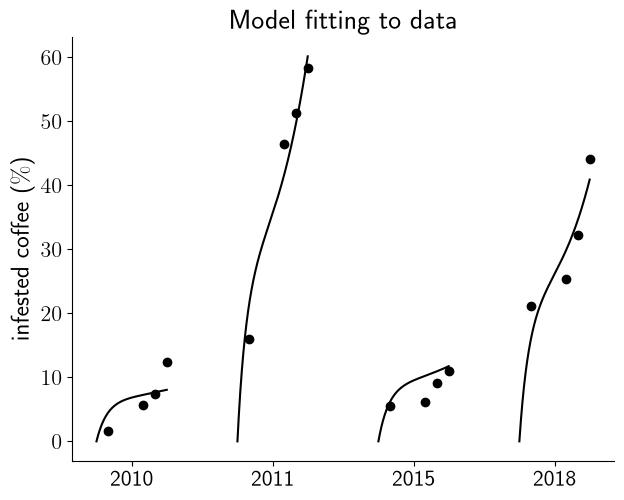

In [3]:
model_fitting = estimation(parameters)
model_fitting.data()
model_fitting.bounds() # set up parameters to estimate and their bounds
opt = model_fitting.solve()
model_fitting.evaluate(opt.x)
model_fitting.printing(opt, df_params)
_, ax = model_fitting.plotting()
plt.show()